# Optimización de hiperparámetros de la LSTM para la predicción de RUL en FD001

El proceso es:

1. Cargar los motores de **validación** que se separaron en el EDA (`EDA.ipynb`)
2. Buscar con Optuna la combinación de hiperparámetros con menor RMSE en validación
3. Reentrenar la mejor configuración con todos los datos de entrenamiento y varias semillas
4. Evaluar **una sola vez** en test y comparar con el baseline

## 1. Librerías y configuración

In [ ]:
import json
import random
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)

In [ ]:
DATA_DIR = Path("data/CMaps/training")
RESULTS_DIR = Path("results/lstm_optuna")
BASELINE_RESULTS = Path("results/lstm_baseline/results.json")

SEED = 42

WINDOW_SIZE = 30
RUL_CAP = 125

# Búsqueda
N_TRIALS = 50
MAX_EPOCHS = 100
PATIENCE = 15

FINAL_SEEDS = [0, 1]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo: {device}")

Dispositivo: cuda


In [26]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(SEED)

## 2. Carga de datos

In [27]:
train_df = pd.read_csv(DATA_DIR / "fd001_train.csv")
val_df = pd.read_csv(DATA_DIR / "fd001_val.csv")
test_df = pd.read_csv(DATA_DIR / "fd001_test.csv")

feature_cols = [
    col for col in train_df.columns if col not in ["engine_id", "time_in_cycles", "RUL"]
]

train_df["RUL"] = train_df["RUL"].clip(upper=RUL_CAP)
val_df["RUL"] = val_df["RUL"].clip(upper=RUL_CAP)
test_df["RUL"] = test_df["RUL"].clip(upper=RUL_CAP)

print(f"Train: {train_df.shape} | Validación: {val_df.shape} | Test: {test_df.shape}")
print(f"Variables ({len(feature_cols)}): {feature_cols}")

Train: (16561, 16) | Validación: (4070, 16) | Test: (13096, 16)
Variables (13): ['T24', 'T30', 'T50', 'P30', 'Nf', 'Nc', 'Ps30', 'phi', 'NRf', 'BPR', 'htBleed', 'W31', 'W32']


## 3. Separación de validación

In [28]:
fit_df = train_df
val_engines = sorted(val_df["engine_id"].unique().tolist())

# Comprobación de que ningún motor está a la vez en entrenamiento y validación
assert not set(val_engines) & set(fit_df["engine_id"].unique())

print(f"Motores de entrenamiento: {fit_df['engine_id'].nunique()}")
print(f"Motores de validación:    {len(val_engines)} -> {val_engines}")

Motores de entrenamiento: 80
Motores de validación:    20 -> [1, 5, 11, 13, 19, 23, 31, 32, 34, 40, 45, 46, 54, 71, 74, 77, 78, 81, 84, 91]


## 4. Ventanas temporales

In [29]:
def create_train_windows(df, feature_cols, window_size):
    windows, targets = [], []
    for _, engine_data in df.groupby("engine_id"):
        features = engine_data[feature_cols].to_numpy()
        rul = engine_data["RUL"].to_numpy()
        for end in range(window_size, len(engine_data) + 1):
            windows.append(features[end - window_size : end])
            targets.append(rul[end - 1])
    return np.array(windows), np.array(targets)


def create_test_windows(df, feature_cols, window_size):
    windows, targets = [], []
    for _, engine_data in df.groupby("engine_id"):
        windows.append(engine_data[feature_cols].to_numpy()[-window_size:])
        targets.append(engine_data["RUL"].iloc[-1])
    return np.array(windows), np.array(targets)


X_fit, y_fit = create_train_windows(fit_df, feature_cols, WINDOW_SIZE)
X_val, y_val = create_train_windows(val_df, feature_cols, WINDOW_SIZE)
X_full, y_full = create_train_windows(
    pd.concat([fit_df, val_df]), feature_cols, WINDOW_SIZE
)
X_test, y_test = create_test_windows(test_df, feature_cols, WINDOW_SIZE)

print(f"X_fit:  {X_fit.shape}  (entrenamiento durante la búsqueda)")
print(f"X_val:  {X_val.shape}   (validación durante la búsqueda)")
print(f"X_full: {X_full.shape}  (entrenamiento final: fit + val)")
print(f"X_test: {X_test.shape}")

X_fit:  (14241, 30, 13)  (entrenamiento durante la búsqueda)
X_val:  (3490, 30, 13)   (validación durante la búsqueda)
X_full: (17731, 30, 13)  (entrenamiento final: fit + val)
X_test: (100, 30, 13)


## 5. Modelo LSTM

In [30]:
class LSTMModel(nn.Module):
    def __init__(self, n_features, hidden_size, num_layers, dropout):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features,
            hidden_size=hidden_size,
            num_layers=num_layers,
            dropout=dropout if num_layers > 1 else 0.0,
            batch_first=True,
        )
        self.dropout = nn.Dropout(dropout)
        self.output_layer = nn.Linear(hidden_size, 1)

    def forward(self, x):
        _, (hidden_state, _) = self.lstm(x)
        last_hidden = hidden_state[-1]
        return self.output_layer(self.dropout(last_hidden)).squeeze(-1)

## 6. Funciones de entrenamiento y evaluación

In [31]:
def make_loader(X, y, batch_size):
    dataset = TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        # Objetivo escalado a [0, 1]
        torch.tensor(y / RUL_CAP, dtype=torch.float32),
    )
    return DataLoader(dataset, batch_size=batch_size, shuffle=True)


def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        optimizer.zero_grad()
        loss = criterion(model(X_batch), y_batch)
        loss.backward()
        optimizer.step()


def predict(model, X):
    model.eval()
    with torch.no_grad():
        X_tensor = torch.tensor(X, dtype=torch.float32).to(device)
        # Se desescala para devolver el RUL en ciclos
        return model(X_tensor).cpu().numpy() * RUL_CAP


def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_pred - y_true) ** 2))


def phm08_score(y_true, y_pred):
    errors = y_pred - y_true
    penalties = np.where(errors < 0, np.exp(-errors / 13) - 1, np.exp(errors / 10) - 1)
    return np.sum(penalties)

## 7. Búsqueda de hiperparámetros con Optuna

Espacio de búsqueda:

| Hiperparámetro | Valores |
|---|---|
| `hidden_size` | 32, 64, 128 |
| `num_layers` | 1, 2, 3 |
| `dropout` | entre 0.0 y 0.5 |
| `learning_rate` | entre 0.0001 y 0.01 (escala logarítmica) |
| `batch_size` | 32, 64, 128, 256 |

Cada trial:

1. Entrena una LSTM con los hiperparámetros propuestos
2. Al final de cada época calcula el RMSE en validación
3. Se para si pasan `PATIENCE` épocas sin mejorar (*early stopping*)
4. Devuelve el mejor RMSE de validación y guarda en qué época se alcanzó

In [32]:
def objective(trial):
    hidden_size = trial.suggest_categorical("hidden_size", [32, 64, 128])
    num_layers = trial.suggest_int("num_layers", 1, 3)
    dropout = trial.suggest_float("dropout", 0.0, 0.5)
    learning_rate = trial.suggest_float("learning_rate", 1e-4, 1e-2, log=True)
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128, 256])

    set_seed(SEED)
    model = LSTMModel(len(feature_cols), hidden_size, num_layers, dropout).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    criterion = nn.MSELoss()
    loader = make_loader(X_fit, y_fit, batch_size)

    best_val_rmse = float("inf")
    best_epoch = 0

    for epoch in range(1, MAX_EPOCHS + 1):
        train_one_epoch(model, loader, optimizer, criterion)
        val_rmse = rmse(y_val, predict(model, X_val))

        if val_rmse < best_val_rmse:
            best_val_rmse = val_rmse
            best_epoch = epoch

        # Poda: Optuna decide si este trial va peor que los anteriores
        trial.report(val_rmse, epoch)
        if trial.should_prune():
            raise optuna.TrialPruned()

        # Early stopping
        if epoch - best_epoch >= PATIENCE:
            break

    trial.set_user_attr("best_epoch", best_epoch)
    return best_val_rmse

In [33]:
study = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=15),
)
study.optimize(objective, n_trials=N_TRIALS)

[I 2026-09-27 18:49:43,835] A new study created in memory with name: no-name-e95551cd-6c21-40dc-a165-edf0de4f4ebd
[I 2026-09-27 18:50:40,020] Trial 0 finished with value: 11.647012329002349 and parameters: {'hidden_size': 64, 'num_layers': 2, 'dropout': 0.07800932022121826, 'learning_rate': 0.00020511104188433984, 'batch_size': 64}. Best is trial 0 with value: 11.647012329002349.
[I 2026-09-27 18:51:41,298] Trial 1 finished with value: 11.692363738926968 and parameters: {'hidden_size': 64, 'num_layers': 1, 'dropout': 0.09091248360355031, 'learning_rate': 0.00023270677083837802, 'batch_size': 64}. Best is trial 0 with value: 11.647012329002349.
[I 2026-09-27 18:52:07,871] Trial 2 finished with value: 11.573230842123214 and parameters: {'hidden_size': 32, 'num_layers': 2, 'dropout': 0.22803499210851796, 'learning_rate': 0.0037183641805732083, 'batch_size': 128}. Best is trial 2 with value: 11.573230842123214.
[I 2026-09-27 18:52:36,738] Trial 3 finished with value: 11.43813049494417 and 

## 8. Resultados de la búsqueda

In [34]:
best_params = study.best_params
best_epoch = study.best_trial.user_attrs["best_epoch"]

n_complete = len([t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE])
n_pruned = len([t for t in study.trials if t.state == optuna.trial.TrialState.PRUNED])

print(f"Trials completados: {n_complete} | Trials podados: {n_pruned}")
print(f"Mejor trial: #{study.best_trial.number}")
print(f"RMSE validación: {study.best_value:.2f} (época {best_epoch})")
print("Mejores hiperparámetros:")
for name, value in best_params.items():
    print(f"  {name:<15}{value}")

Trials completados: 40 | Trials podados: 10
Mejor trial: #3
RMSE validación: 11.44 (época 45)
Mejores hiperparámetros:
  hidden_size    32
  num_layers     3
  dropout        0.4828160165372797
  learning_rate  0.004138040112561018
  batch_size     128


Los 10 mejores trials:

In [35]:
trials_df = study.trials_dataframe(
    attrs=("number", "value", "params", "user_attrs", "state")
)
trials_df = trials_df.rename(
    columns=lambda col: col.replace("params_", "").replace("user_attrs_", "")
)
trials_df = trials_df.rename(columns={"value": "val_rmse"})

trials_df[trials_df["state"] == "COMPLETE"].sort_values("val_rmse").head(10)

,number,val_rmse,batch_size,dropout,hidden_size,learning_rate,num_layers,best_epoch,state
3,3,11.438130,128,0.482816,32,0.004138,3,45.0,COMPLETE
26,26,11.455473,128,0.176359,32,0.009144,1,14.0,COMPLETE
11,11,11.519034,128,0.329938,32,0.004671,2,19.0,COMPLETE
36,36,11.524380,128,0.283605,32,0.001180,3,48.0,COMPLETE
22,22,11.530569,128,0.304854,32,0.001542,2,43.0,COMPLETE
31,31,11.551420,128,0.135940,32,0.002501,2,32.0,COMPLETE
38,38,11.563446,128,0.410176,32,0.000855,3,48.0,COMPLETE
2,2,11.573231,128,0.228035,32,0.003718,2,47.0,COMPLETE
15,15,11.577424,64,0.491105,32,0.003206,2,28.0,COMPLETE
18,18,11.604227,128,0.471680,32,0.001634,2,37.0,COMPLETE


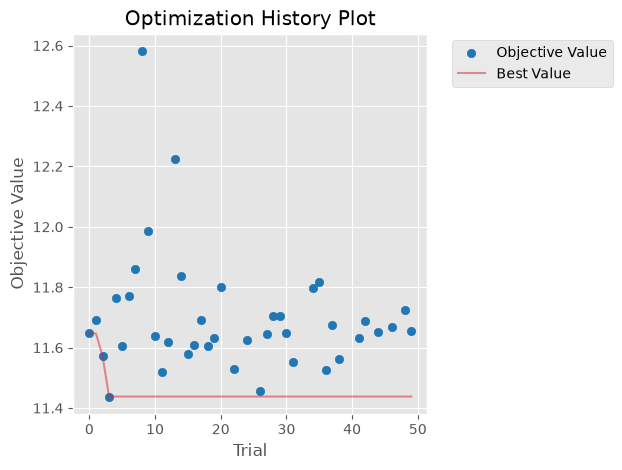

In [47]:
optuna.visualization.matplotlib.plot_optimization_history(study)
plt.show()

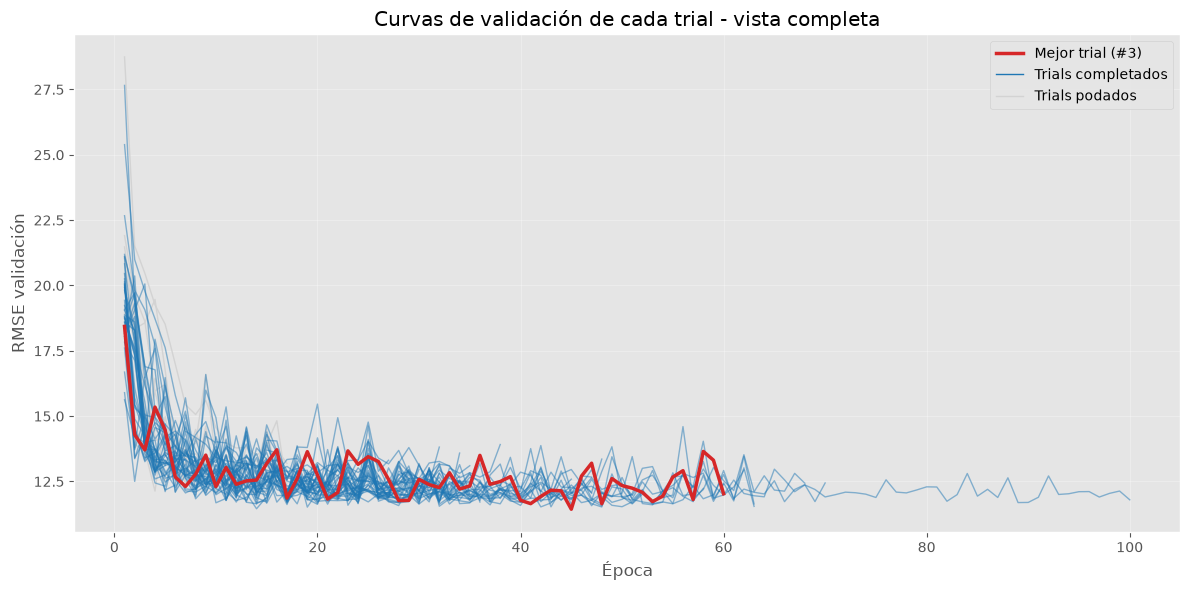

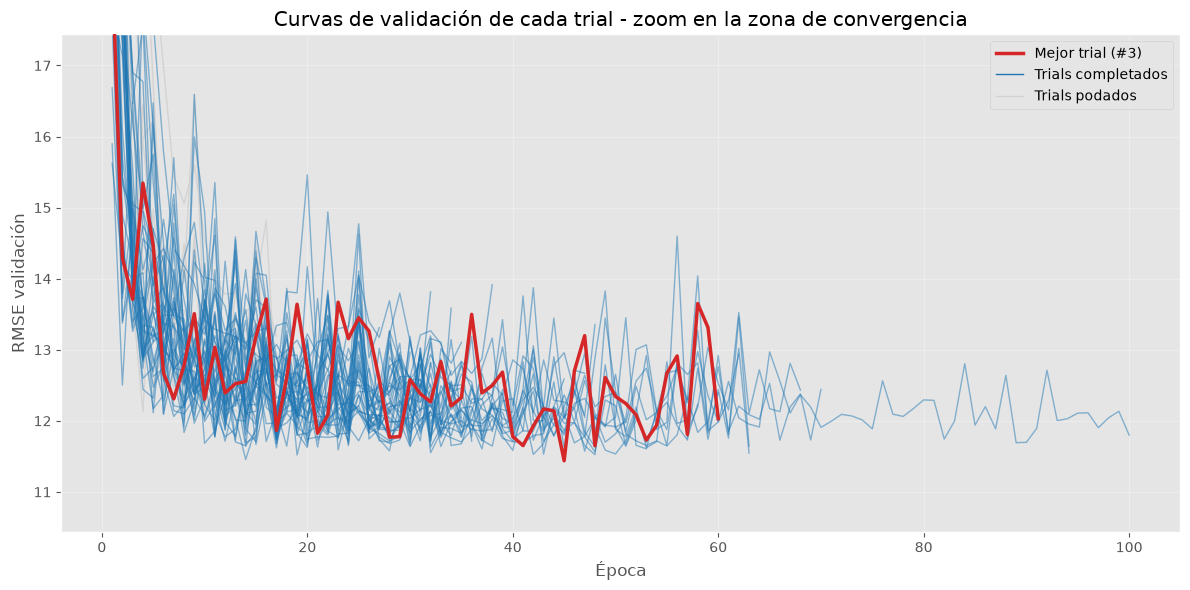

In [48]:
def plot_trial_curves(ax):
    for trial in study.trials:
        # RMSE de validación registrado en cada época con trial.report
        epochs = list(trial.intermediate_values.keys())
        val_rmses = list(trial.intermediate_values.values())

        if trial.number == study.best_trial.number:
            style = {"color": "tab:red", "linewidth": 2.5, "zorder": 3}
        elif trial.state == optuna.trial.TrialState.PRUNED:
            style = {"color": "lightgray", "linewidth": 1, "zorder": 1}
        else:
            style = {"color": "tab:blue", "linewidth": 1, "alpha": 0.5, "zorder": 2}

        ax.plot(epochs, val_rmses, **style)

    # Líneas vacías solo para construir una leyenda con tres entradas
    ax.plot([], [], color="tab:red", linewidth=2.5, label=f"Mejor trial (#{study.best_trial.number})")
    ax.plot([], [], color="tab:blue", linewidth=1, label="Trials completados")
    ax.plot([], [], color="lightgray", linewidth=1, label="Trials podados")

    ax.set_xlabel("Época")
    ax.set_ylabel("RMSE validación")
    ax.grid(alpha=0.3)
    ax.legend()


# Vista completa
fig, ax = plt.subplots(figsize=(12, 6))
plot_trial_curves(ax)
ax.set_title("Curvas de validación de cada trial - vista completa")
plt.tight_layout()
plt.show()

# Zoom en la zona de convergencia
fig, ax = plt.subplots(figsize=(12, 6))
plot_trial_curves(ax)
ax.set_ylim(study.best_value - 1, study.best_value + 6)
ax.set_title("Curvas de validación de cada trial - zoom en la zona de convergencia")
plt.tight_layout()
plt.show()

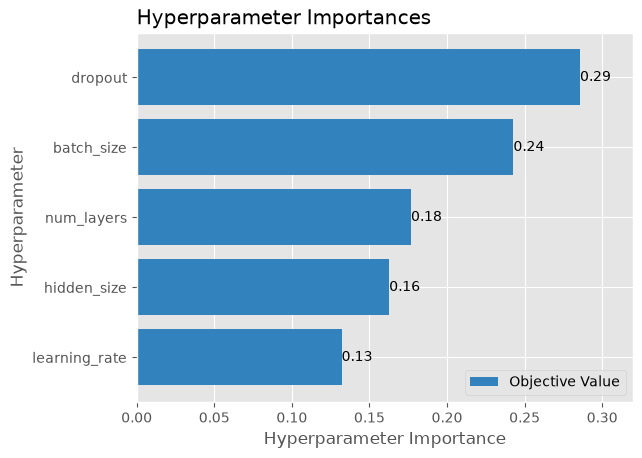

In [38]:
optuna.visualization.matplotlib.plot_param_importances(study)
plt.show()

## 9. Entrenamiento final y evaluación en test


In [43]:
test_results = []
test_predictions = []

for seed in FINAL_SEEDS:
    set_seed(seed)
    model = LSTMModel(
        len(feature_cols),
        best_params["hidden_size"],
        best_params["num_layers"],
        best_params["dropout"],
    ).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=best_params["learning_rate"])
    criterion = nn.MSELoss()
    loader = make_loader(X_full, y_full, best_params["batch_size"])

    for epoch in range(best_epoch):
        train_one_epoch(model, loader, optimizer, criterion)

    y_pred = predict(model, X_test)
    test_predictions.append(y_pred)
    test_results.append(
        {
            "seed": seed,
            "test_rmse": rmse(y_test, y_pred),
            "test_phm08_score": phm08_score(y_test, y_pred),
        }
    )

    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    torch.save(model.state_dict(), RESULTS_DIR / f"lstm_optuna_seed{seed}.pt")
    print(
        f"Semilla {seed} | RMSE test: {test_results[-1]['test_rmse']:.2f} | Score PHM08: {test_results[-1]['test_phm08_score']:.2f}"
    )

test_results_df = pd.DataFrame(test_results)

Semilla 0 | RMSE test: 13.53 | Score PHM08: 305.13
Semilla 1 | RMSE test: 15.37 | Score PHM08: 583.15


In [44]:
rmse_mean, rmse_std = (
    test_results_df["test_rmse"].mean(),
    test_results_df["test_rmse"].std(),
)
score_mean, score_std = (
    test_results_df["test_phm08_score"].mean(),
    test_results_df["test_phm08_score"].std(),
)

with open(BASELINE_RESULTS) as file:
    baseline_metrics = json.load(file)["metrics"]

print(f"{'':<22}{'RMSE test':>14}{'Score PHM08':>18}")
print(
    f"{'Baseline (1 semilla)':<22}{baseline_metrics['test_rmse']:>14.2f}{baseline_metrics['test_phm08_score']:>18.2f}"
)
print(
    f"{'LSTM optimizada':<22}{f'{rmse_mean:.2f} ± {rmse_std:.2f}':>14}{f'{score_mean:.2f} ± {score_std:.2f}':>18}"
)

                           RMSE test       Score PHM08
Baseline (1 semilla)           13.93            435.80
LSTM optimizada         14.45 ± 1.30   444.14 ± 196.59


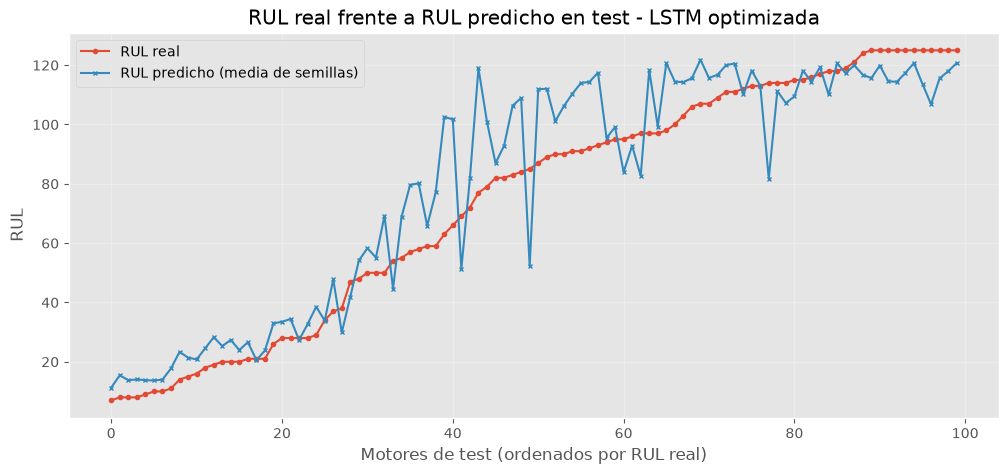

In [45]:
mean_prediction = np.mean(test_predictions, axis=0)
order = np.argsort(y_test)

plt.figure(figsize=(12, 5))
plt.plot(y_test[order], label="RUL real", marker="o", markersize=3)
plt.plot(
    mean_prediction[order],
    label="RUL predicho (media de semillas)",
    marker="x",
    markersize=3,
)
plt.title("RUL real frente a RUL predicho en test - LSTM optimizada")
plt.xlabel("Motores de test (ordenados por RUL real)")
plt.ylabel("RUL")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 10. Guardado de resultados

In [42]:
trials_df.to_csv(RESULTS_DIR / "optuna_trials.csv", index=False)

best_model = LSTMModel(
    len(feature_cols),
    best_params["hidden_size"],
    best_params["num_layers"],
    best_params["dropout"],
)

results = {
    "hyperparameters": {
        **best_params,
        "window_size": WINDOW_SIZE,
        "rul_cap": RUL_CAP,
        "epochs": best_epoch,
    },
    "search": {
        "n_trials": N_TRIALS,
        "n_complete": n_complete,
        "n_pruned": n_pruned,
        "n_val_engines": len(val_engines),
        "best_val_rmse": float(study.best_value),
    },
    "n_features": len(feature_cols),
    "trainable_parameters": sum(p.numel() for p in best_model.parameters()),
    "metrics": {
        "test_rmse_mean": float(rmse_mean),
        "test_rmse_std": float(rmse_std),
        "test_phm08_score_mean": float(score_mean),
        "test_phm08_score_std": float(score_std),
        "per_seed": [
            {
                "seed": r["seed"],
                "test_rmse": float(r["test_rmse"]),
                "test_phm08_score": float(r["test_phm08_score"]),
            }
            for r in test_results
        ],
    },
}

with open(RESULTS_DIR / "results.json", "w") as file:
    json.dump(results, file, indent=4)

print(json.dumps(results, indent=4))

{
    "hyperparameters": {
        "hidden_size": 32,
        "num_layers": 3,
        "dropout": 0.4828160165372797,
        "learning_rate": 0.004138040112561018,
        "batch_size": 128,
        "window_size": 30,
        "rul_cap": 125,
        "epochs": 45
    },
    "search": {
        "n_trials": 50,
        "n_complete": 40,
        "n_pruned": 10,
        "n_val_engines": 20,
        "best_val_rmse": 11.43813049494417
    },
    "n_features": 13,
    "trainable_parameters": 22945,
    "metrics": {
        "test_rmse_mean": 14.4506884751633,
        "test_rmse_std": 1.3047134040559238,
        "test_phm08_score_mean": 444.1378339754755,
        "test_phm08_score_std": 196.5918354887694,
        "per_seed": [
            {
                "seed": 0,
                "test_rmse": 13.528116779650373,
                "test_phm08_score": 305.1264139754565
            },
            {
                "seed": 1,
                "test_rmse": 15.373260170676229,
                "test_p